# DSC 670 — Week 6: Fine-Tuning and Testing DistilBERT

For this assignment, I follow the assigned tutorial to fine-tune DistilBERT on IMDb movie reviews. The goal is to predict whether a review is positive or negative, then check how well the model handles reviews it hasn't trained on. Getting the training cell to finish is a good start, but I also want to see where the predictions fall apart.

I keep the tutorial's small training setup: **2,000 training reviews, two epochs, and 500 test reviews** (Sangeethasaravanan, 2025). I add **400 validation reviews** to help choose the model without using the final test results. I also try a few original examples to see what the overall score might miss.

Despite “from scratch” in the article's title, I'm starting with a pretrained model. This is fine-tuning a sentiment classifier, rather than training a language model from the beginning or building a chatbot. Hugging Face's text-classification guide provides another reference for this approach (Hugging Face, n.d.-a).

**Run completed:** October 17, 2026, using a Tesla T4 GPU in Google Colab. The training results, charts, and predictions below are retained from that run.

## Notebook environment

I use Google Colab for the GPU required by the assignment. Colab notebooks already use the Jupyter `.ipynb` format, so I can train there and keep the code, results, and discussion together in one file (Google, n.d.). This version follows the Hugging Face workflow rather than using Azure OpenAI.

## 1. Set up the environment

I use specific versions of the main training libraries to reduce surprises from package updates. I also keep Colab's installed PyTorch so its GPU support stays available. A few argument names have changed since older examples were written, so I use the names supported by this version of Transformers (Hugging Face, n.d.-b).

In [1]:
#Keep the training libraries on a known API version while retaining Colab's GPU-enabled PyTorch.
%pip install -q "transformers==4.57.1" "datasets==4.3.0" "accelerate==1.11.0" "scikit-learn>=1.5,<2" pandas matplotlib


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 60.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 20.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 375.8/375.8 kB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.7/119.7 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199.3/199.3 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 74.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.9.0 which is incompatible.
diffuser

**Output:**

The installation reports dependency conflicts involving packages already in Colab. I leave those warnings visible rather than treating this as a completely clean setup. The libraries needed for this notebook load successfully in the next step, and the training and testing cells finish without errors.

## 2. Check the GPU and record the settings

Before training, I check that Colab has assigned a GPU and record the settings for this run. I use a fixed seed to keep the review selection consistent if I repeat the experiment, although results can still vary between environments.

I use small batches of eight reviews and a 256-token limit to keep the run manageable. That limit means longer reviews will be shortened, so I check how often that happens rather than assuming it's a harmless shortcut.

In [2]:
#Use the PyTorch workflow without loading optional TensorFlow or Flax integrations.
import os
os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import json
import platform
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from datasets import Dataset, DatasetDict, load_dataset
from scipy.special import softmax
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, f1_score,
    precision_score, recall_score,
)
from sklearn.model_selection import train_test_split
from transformers import (
    AutoModelForSequenceClassification, AutoTokenizer,
    DataCollatorWithPadding, Trainer, TrainingArguments, set_seed,
)

#Stop early if Colab has not assigned a GPU.
if not torch.cuda.is_available():
    raise RuntimeError("Select Runtime > Change runtime type > GPU, then rerun this cell.")

#Keep the sample selection and model initialization repeatable within this environment.
SEED = 42
MODEL_ID = "distilbert/distilbert-base-uncased"
N_TRAIN, N_VALIDATION, N_TEST = 2000, 400, 500
MAX_LENGTH = 256
RUN_DIR = Path("/content/dsc670_week6")
RUN_DIR.mkdir(parents=True, exist_ok=True)
set_seed(SEED)

#Record the environment and experiment choices alongside the eventual results.
run_info = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "transformers": version("transformers"),
    "datasets": version("datasets"),
    "accelerate": version("accelerate"),
    "gpu": torch.cuda.get_device_name(0),
    "model": MODEL_ID,
    "seed": SEED,
    "max_tokens": MAX_LENGTH,
    "training_reviews": N_TRAIN,
    "validation_reviews": N_VALIDATION,
    "test_reviews": N_TEST,
    "epochs": 2,
    "batch_size": 8,
    "learning_rate": 2e-5,
}
display(pd.Series(run_info, name="Run setting").to_frame())


,Run setting
python,3.13.15
torch,2.11.0+cu130
transformers,4.57.1
datasets,4.3.0
accelerate,1.11.0
gpu,Tesla T4
model,distilbert/distilbert-base-uncased
seed,42
max_tokens,256
training_reviews,2000


**Output:**

Colab assigns a Tesla T4 GPU. The recorded environment uses Python 3.13.15, PyTorch 2.11.0+cu130, and Transformers 4.57.1. The settings match the planned 2,000 training reviews, 400 validation reviews, 500 test reviews, and two epochs, so I can move on to preparing the data.

## 3. Select the reviews and keep the groups separate

I use IMDb's existing sentiment labels instead of creating my own dataset. It has 25,000 labeled training reviews and 25,000 labeled test reviews; I don't use the separate unlabeled reviews (Hugging Face, n.d.-c).

I remove exact duplicate text before sampling and check that no selected review appears in more than one group. Otherwise, the model could get credit for predicting something it has already seen. This doesn't catch every possible similarity between reviews, but it handles exact copies.

The training reviews teach the model, the validation reviews help select the better epoch, and the test reviews provide the final evaluation. I sample by sentiment so both positive and negative reviews stay well represented.

In [3]:
#Use the supplied IMDb labels rather than creating a new training dataset.
raw = load_dataset("stanfordnlp/imdb")
#Remove exact duplicates before selecting the working samples.
train_pool = raw["train"].to_pandas()[["text", "label"]].drop_duplicates("text")
test_pool = raw["test"].to_pandas()[["text", "label"]].drop_duplicates("text")
#Exclude original-training text from the test pool to prevent exact-text leakage.
test_pool = test_pool.loc[~test_pool["text"].isin(train_pool["text"])]

#Stratify the sample to preserve approximately the original sentiment proportions.
selected_train, _ = train_test_split(
    train_pool, train_size=N_TRAIN + N_VALIDATION,
    stratify=train_pool["label"], random_state=SEED,
)
#Reserve validation reviews from the training source for checkpoint selection.
train_df, validation_df = train_test_split(
    selected_train, test_size=N_VALIDATION,
    stratify=selected_train["label"], random_state=SEED,
)
#Keep the final test sample outside the training and validation workflow.
test_df, _ = train_test_split(
    test_pool, train_size=N_TEST,
    stratify=test_pool["label"], random_state=SEED,
)
frames = {
    "train": train_df.reset_index(drop=True),
    "validation": validation_df.reset_index(drop=True),
    "test": test_df.reset_index(drop=True),
}
train_df, validation_df, test_df = (frames[key] for key in ("train", "validation", "test"))

#Verify pairwise separation using full review text rather than row positions.
text_sets = {name: set(frame["text"]) for name, frame in frames.items()}
assert not (text_sets["train"] & text_sets["validation"])
assert not (text_sets["train"] & text_sets["test"])
assert not (text_sets["validation"] & text_sets["test"])
assert all(not frame.isna().any().any() for frame in frames.values())

#Convert the selected frames back to Hugging Face datasets for tokenization.
splits = DatasetDict({
    name: Dataset.from_pandas(frame, preserve_index=False)
    for name, frame in frames.items()
})
split_counts = pd.DataFrame({
    name: frame["label"].value_counts().reindex([0, 1], fill_value=0)
    for name, frame in frames.items()
}).T.rename(columns={0: "Negative", 1: "Positive"})
split_counts["Total"] = split_counts.sum(axis=1)
display(split_counts)
display(Markdown("**Checks passed:** the selected splits contain no exact shared review text or missing values."))


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

plain_text/test-00000-of-00001.parquet:   0%|          | 0.00/20.5M [00:00<?, ?B/s]

plain_text/unsupervised-00000-of-00001.p(…):   0%|          | 0.00/42.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

label,Negative,Positive,Total
train,998,1002,2000
validation,200,200,400
test,249,251,500


**Checks passed:** the selected splits contain no exact shared review text or missing values.

**Output:**

The training group has 998 negative and 1,002 positive reviews, validation has 200 of each, and the test group has 249 negative and 251 positive reviews. The classes are nearly balanced, so neither sentiment dominates the exercise. The checks also confirm that these groups have no exact shared review text or missing values.

## 4. Prepare the text

I use DistilBERT's matching tokenizer to turn the review text into the inputs the model expects. I keep up to 256 tokens per review and add padding within each batch, rather than making every review the same maximum length.

This keeps the workload smaller, but it also means the model may miss part of a long review. I measure the original training-review lengths so I can discuss that tradeoff using the actual data.

In [4]:
#Match the tokenizer vocabulary to the pretrained checkpoint.
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
#Measure original lengths before truncation so the information loss can be reported.
train_lengths = np.array([
    len(ids) for ids in tokenizer(
        train_df["text"].tolist(), truncation=False, verbose=False
    )["input_ids"]
])

def tokenize_batch(batch):
    #Cap input length to reduce memory use during this small Colab run.
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized = splits.map(tokenize_batch, batched=True, remove_columns=["text"])
tokenized = tokenized.rename_column("label", "labels")
#Pad within each batch instead of padding every review to 256 tokens.
data_collator = DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8)

display(pd.Series({
    "Median training-review tokens": float(np.median(train_lengths)),
    "Training reviews exceeding limit (%)": float(100 * np.mean(train_lengths > MAX_LENGTH)),
    "Maximum input tokens retained": MAX_LENGTH,
}).to_frame("Value"))
display(tokenized)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

,Value
Median training-review tokens,232.0
Training reviews exceeding limit (%),44.4
Maximum input tokens retained,256.0


DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 2000
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 400
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 500
    })
})

**Output:**

The median training review is 232 tokens long, but **44.4% of training reviews exceed the 256-token limit**. That's a substantial share of reviews being shortened. It doesn't mean 44.4% of all text is removed, but it does mean the model won't see the ending of many longer reviews. That could matter when a reviewer saves their overall opinion for the end.

## 5. Choose the model and a comparison

DistilBERT starts with pretrained language weights, but its new positive-or-negative prediction layer still needs training. I allow all model parameters to update during fine-tuning.

I track accuracy because it's easy to interpret, along with macro F1, which gives both sentiment classes equal weight. Validation macro F1 determines which saved version of the model I keep.

For a simple comparison, I also use a baseline that always predicts the most common label in the training sample. The model should do better than just guessing the same answer every time. This comparison won't tell me how it performs against another trained sentiment model.

In [5]:
#Keep numeric dataset labels and readable prediction labels consistent.
id2label = {0: "NEGATIVE", 1: "POSITIVE"}
label2id = {label: index for index, label in id2label.items()}
#Load pretrained language weights with a newly initialized two-class prediction head.
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID, num_labels=2, id2label=id2label, label2id=label2id,
)

def compute_metrics(eval_prediction):
    logits, labels = eval_prediction
    #Accept either a logits array or the tuple returned by some model configurations.
    if isinstance(logits, tuple):
        logits = logits[0]
    #Choose the higher-scoring sentiment label for each review.
    predictions = np.argmax(logits, axis=-1)
    #Weight both sentiment classes equally in the macro metrics.
    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision_macro": precision_score(labels, predictions, average="macro", zero_division=0),
        "recall_macro": recall_score(labels, predictions, average="macro", zero_division=0),
        "f1_macro": f1_score(labels, predictions, average="macro", zero_division=0),
    }

#Confirm whether the whole model is trainable rather than only its classification head.
display(pd.Series({
    "Total parameters": sum(p.numel() for p in model.parameters()),
    "Trainable parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
}).to_frame("Count"))


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


,Count
Total parameters,66955010
Trainable parameters,66955010


**Output:**

Both the total and trainable parameter counts are **66,955,010**, confirming that I'm fine-tuning the whole model. The warning about newly initialized classification weights is expected: those weights still need to learn the sentiment task. The pretrained model gives me a starting point, but it doesn't make the new prediction layer useful automatically.

## 6. Fine-tune for two epochs

I keep the tutorial's two epochs and batch size, and use the small learning rate from Hugging Face's classification example (Hugging Face, n.d.-a). The idea is to adjust the model gradually rather than make large changes all at once.

After each pass through the training reviews, I check performance on the validation group. The notebook keeps the version with the better validation macro F1. I leave the test reviews out of that decision so they can serve as a separate check afterward.

In [6]:
#Use a small two-epoch run with validation after each pass through the training sample.
training_args = TrainingArguments(
    output_dir=str(RUN_DIR / "checkpoints"),
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=2,
    weight_decay=0.01,
    warmup_ratio=0.1,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    #Select the checkpoint by validation macro F1 rather than by test performance.
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    save_total_limit=2,
    #Use mixed precision on compatible GPUs to reduce memory requirements.
    fp16=torch.cuda.get_device_capability(0)[0] >= 7,
    bf16=False,
    optim="adamw_torch",
    #Avoid external experiment tracking and automatic model uploads.
    report_to="none",
    push_to_hub=False,
    seed=SEED,
    data_seed=SEED,
    dataloader_num_workers=0,
)
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized["train"],
    #Validation guides checkpoint selection; the test set remains untouched.
    eval_dataset=tokenized["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)
#Update model weights using labeled training reviews.
training_result = trainer.train()
#Retain the actual training history for plots and written evaluation.
training_log = pd.DataFrame(trainer.state.log_history)
display(pd.Series(training_result.metrics).to_frame("Training result"))


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
1,0.477000,0.299484,0.897500,0.901120,0.897500,0.897268
2,0.240200,0.329383,0.900000,0.900040,0.900000,0.899997


,Training result
train_runtime,7.907700e+01
train_samples_per_second,5.058400e+01
train_steps_per_second,6.323000e+00
total_flos,2.646699e+14
train_loss,3.585994e-01
epoch,2.000000e+00


**Output:**

The run completes both epochs and 500 training steps in about **79 seconds**. Validation accuracy moves from 89.75% to 90.00%, and validation macro F1 increases from 0.8973 to 0.9000. The second epoch is selected because its macro F1 is slightly higher. That accuracy change is only one additional correct review out of 400, so I wouldn't describe it as a major improvement.

## 7. Look at the learning pattern

I plot the training and validation results together to see whether more training is helping with unfamiliar reviews or mostly helping with the training examples. A lower training loss alone doesn't answer that question. With only two epochs, I'm looking for warning signs rather than claiming a clear long-term trend.

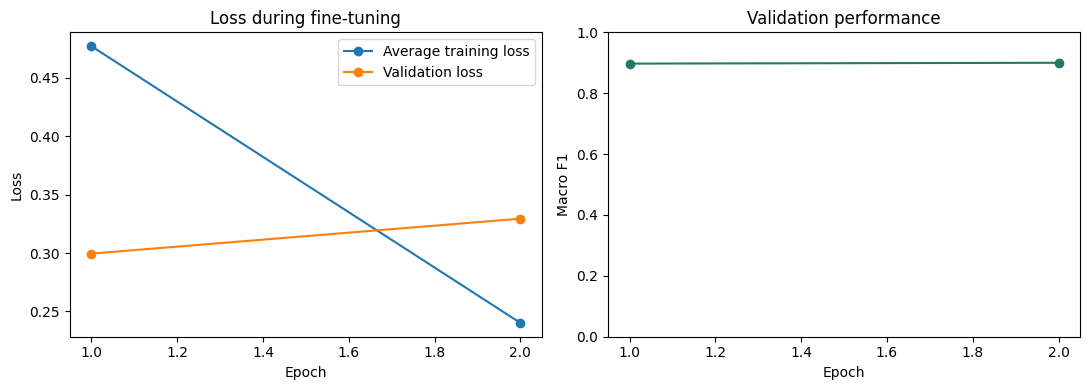

,epoch,eval_loss,eval_f1_macro
0,1.0,0.299484,0.897268
1,2.0,0.329383,0.899997


In [7]:
#Separate training averages from the epoch-end validation measurements.
train_history = training_log.loc[training_log["loss"].notna(), ["epoch", "loss"]]
validation_history = training_log.loc[
    training_log["eval_loss"].notna(), ["epoch", "eval_loss", "eval_f1_macro"]
]
#Compare loss patterns and validation F1 without using the final test sample.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(train_history["epoch"], train_history["loss"], marker="o", label="Average training loss")
axes[0].plot(validation_history["epoch"], validation_history["eval_loss"], marker="o", label="Validation loss")
axes[0].set(title="Loss during fine-tuning", xlabel="Epoch", ylabel="Loss")
axes[0].legend()
axes[1].plot(validation_history["epoch"], validation_history["eval_f1_macro"], marker="o", color="#217A68")
axes[1].set(title="Validation performance", xlabel="Epoch", ylabel="Macro F1", ylim=(0, 1))
fig.tight_layout()
#Save the figure as supporting evidence from this run.
fig.savefig(RUN_DIR / "learning_curves.png", dpi=150)
plt.show()
display(validation_history.reset_index(drop=True))


**Output:**

Training loss drops from 0.4770 to 0.2402, while validation loss rises from 0.2995 to 0.3294. Combined with the small gain in validation F1, this suggests the second epoch helps much more with fitting the training reviews than with improving predictions on validation reviews. It could be an early sign of overfitting, but two epochs aren't enough to establish a clear trend. I don't see a strong reason here to assume that simply training longer would keep improving the results.

## 8. Test on held-out reviews

Now I evaluate the selected model on the 500 test reviews. I compare its scores with the majority-label baseline and use a confusion matrix to see which kinds of mistakes it makes.

These are still IMDb movie reviews, so the results tell me about this task. They don't establish that the same model would work equally well on product reviews, social media, or other languages.

,Accuracy,Macro precision,Macro recall,Macro F1
Fine-tuned DistilBERT,0.884,0.8842,0.884,0.8840
Training-majority baseline,0.502,0.2510,0.500,0.3342


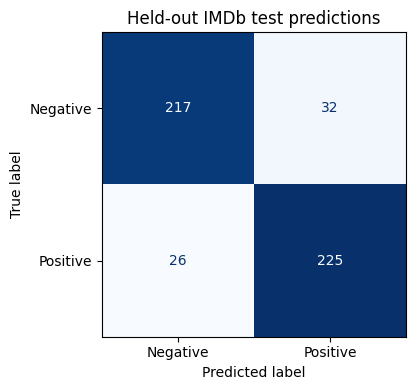

In [8]:
#Evaluate the selected checkpoint on held-out test reviews only after training is complete.
test_output = trainer.predict(tokenized["test"], metric_key_prefix="test")
test_logits = test_output.predictions
if isinstance(test_logits, tuple):
    test_logits = test_logits[0]
y_true = test_output.label_ids
y_pred = np.argmax(test_logits, axis=-1)
#These softmax scores are not calibrated probabilities of correctness.
test_probabilities = softmax(test_logits, axis=-1)

#Choose the baseline label from training data, not from test labels.
majority_label = int(train_df["label"].mode().iloc[0])
baseline_predictions = np.full_like(y_true, majority_label)

#Apply the same metrics to the trained model and the majority-class reference.
def score_labels(truth, predictions):
    return {
        "Accuracy": accuracy_score(truth, predictions),
        "Macro precision": precision_score(truth, predictions, average="macro", zero_division=0),
        "Macro recall": recall_score(truth, predictions, average="macro", zero_division=0),
        "Macro F1": f1_score(truth, predictions, average="macro", zero_division=0),
    }

results_table = pd.DataFrame({
    "Fine-tuned DistilBERT": score_labels(y_true, y_pred),
    "Training-majority baseline": score_labels(y_true, baseline_predictions),
}).T
display(results_table.round(4))
fig, ax = plt.subplots(figsize=(5, 4))
#Keep the label order explicit so both error directions are interpreted correctly.
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=[0, 1], display_labels=["Negative", "Positive"],
    cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title("Held-out IMDb test predictions")
fig.tight_layout()
fig.savefig(RUN_DIR / "confusion_matrix.png", dpi=150)
plt.show()


**Output:**

The model correctly classifies **442 of 500 test reviews**, giving it **88.4% accuracy and a macro F1 of 0.8840**. The baseline always predicts positive and scores 50.2% accuracy. The model is ahead by **38.2 percentage points**, which is a useful improvement over that simple approach.

The confusion matrix shows 32 negative reviews predicted as positive and 26 positive reviews predicted as negative. Mistakes happen in both directions, with slightly more negative reviews being missed. Test accuracy is also 1.6 percentage points below validation accuracy, so the result is a little lower on this separate sample.

## 9. Take a closer look at mistakes

An overall score can hide some interesting failures, so I look at five wrong predictions with the highest prediction scores. I want to see whether the model can be very sure of an answer and still get it wrong.

These scores show how strongly the model favors one label. They aren't a guarantee that the prediction is correct. The displayed review excerpts are also shortened, so I avoid guessing why a particular mistake happened without seeing the full context.

In [9]:
#Align each prediction with its original test review and a stable row position.
test_details = test_df.copy()
test_details["test_row"] = np.arange(len(test_details))
test_details["actual"] = [id2label[int(label)] for label in y_true]
test_details["predicted"] = [id2label[int(label)] for label in y_pred]
test_details["predicted_class_score"] = test_probabilities.max(axis=1)
#Shorten displayed text while keeping the complete review in the saved results.
test_details["review_excerpt"] = test_details["text"].str.slice(0, 600)
#Inspect high-scoring mistakes to avoid equating confident predictions with correct ones.
errors = test_details.loc[y_true != y_pred].sort_values("predicted_class_score", ascending=False)
#Handle a perfect sample without claiming perfect general performance.
if errors.empty:
    display(Markdown("No mistakes occurred in this test sample. This does not establish perfect performance outside the sample."))
else:
    display(errors[["test_row", "actual", "predicted", "predicted_class_score", "review_excerpt"]].head(5))


,test_row,actual,predicted,predicted_class_score,review_excerpt
479,479,NEGATIVE,POSITIVE,0.991844,The Adventures of Sebastian Cole is about a bo...
240,240,NEGATIVE,POSITIVE,0.990839,"It's schmaltzy, but then what else did you exp..."
75,75,POSITIVE,NEGATIVE,0.990044,I own a Video store with hundreds of documenta...
118,118,POSITIVE,NEGATIVE,0.989731,I don't know if I'd go as far as to say that t...
196,196,NEGATIVE,POSITIVE,0.989531,"It's partly bad luck for ""Illuminata"" that it ..."


**Output:**

Test review 479 stands out: its actual label is negative, but the model predicts positive with a score of 0.9918. The other displayed mistakes also have scores above 0.98. A very high score clearly doesn't make an answer correct.

The shortened excerpts don't give me enough information to say what caused these mistakes. Mixed opinions, wording, or truncation could be worth investigating, but I can't attribute a specific error to one of those explanations from this display alone.

## 10. Try a few new reviews

I test six original examples to make the results easier to interpret. Four have an intended positive or negative meaning, including one sarcastic review. The other two are mixed or neutral and don't have one expected binary answer.

This is a small spot check, not another reliable accuracy estimate. I'm interested in what happens when the wording gets less straightforward, especially since the model can only choose positive or negative.

In [10]:
#Probe straightforward, negated, sarcastic, mixed, and neutral wording beyond the dataset.
new_reviews = pd.DataFrame([
    {"text": "I loved this movie. The performances were excellent and the ending was satisfying.", "intended": "POSITIVE"},
    {"text": "The movie was dull, confusing, and far too long. I would not recommend it.", "intended": "NEGATIVE"},
    {"text": "I expected to hate this movie, but I ended up loving it. It was funny and surprisingly moving.", "intended": "POSITIVE"},
    {"text": "Wonderful. Another ninety minutes of terrible acting that I will never get back.", "intended": "NEGATIVE"},
    {"text": "The actors were great, but the story was disappointing. Some scenes worked and others did not.", "intended": "MIXED: no single expected label"},
    {"text": "The film runs for ninety minutes and was released on a Friday.", "intended": "NEUTRAL: no expected binary label"},
])
#Disable training-time dropout for these inference examples.
trainer.model.eval()
#Apply the same input limit and place tensors on the model's current device.
inputs = tokenizer(
    new_reviews["text"].tolist(), return_tensors="pt", padding=True,
    truncation=True, max_length=MAX_LENGTH,
).to(trainer.model.device)
#Run predictions without storing gradients or changing model weights.
with torch.inference_mode():
    new_logits = trainer.model(**inputs).logits.float().cpu().numpy()
new_probabilities = softmax(new_logits, axis=-1)
#The binary classifier must choose a label even for neutral or mixed text.
new_reviews["prediction"] = [id2label[int(label)] for label in new_probabilities.argmax(axis=1)]
new_reviews["predicted_class_score"] = new_probabilities.max(axis=1)
with pd.option_context("display.max_colwidth", 150):
    display(new_reviews)


,text,intended,prediction,predicted_class_score
0,I loved this movie. The performances were excellent and the ending was satisfying.,POSITIVE,POSITIVE,0.989306
1,"The movie was dull, confusing, and far too long. I would not recommend it.",NEGATIVE,NEGATIVE,0.986284
2,"I expected to hate this movie, but I ended up loving it. It was funny and surprisingly moving.",POSITIVE,POSITIVE,0.989511
3,Wonderful. Another ninety minutes of terrible acting that I will never get back.,NEGATIVE,POSITIVE,0.633609
4,"The actors were great, but the story was disappointing. Some scenes worked and others did not.",MIXED: no single expected label,NEGATIVE,0.939471
5,The film runs for ninety minutes and was released on a Friday.,NEUTRAL: no expected binary label,POSITIVE,0.885532


**Output:**

The model handles the straightforward positive and negative reviews correctly, along with the review that changes from expecting disappointment to enjoying the movie. It gets the sarcastic review wrong, calling “Wonderful. Another ninety minutes of terrible acting that I will never get back” positive with a score of 0.6336. Apparently, “Wonderful” is doing a little too much heavy lifting in that prediction, although this example alone can't tell me exactly why it failed.

That's three correct predictions out of the four examples with intended binary labels. The mixed review is classified as negative with a score of 0.9395, and the neutral statement is classified as positive with a score of 0.8855. Neither has one expected binary answer. The model has to pick a side even when the text doesn't fit either option very well.

## 11. Save the model and results

I save the model with its matching tokenizer, along with the settings, predictions, and evaluation results. Keeping these together would make it easier to revisit the experiment without starting over.

The saved model files stay separate from this notebook. The notebook retains the visible results and discussion, while any model files I want to reuse need to be downloaded before the temporary Colab session is cleared.

In [11]:
import hashlib

#Save the model and its matching tokenizer so they can be used together later.
model_dir = RUN_DIR / "fine_tuned_distilbert"
trainer.save_model(str(model_dir))
tokenizer.save_pretrained(str(model_dir))
trainer.save_state()
#Preserve numerical results and individual predictions for the final commentary.
results_table.to_csv(RUN_DIR / "test_metrics.csv")
training_log.to_csv(RUN_DIR / "training_log.csv", index=False)
test_details.to_csv(RUN_DIR / "test_predictions.csv", index=False)
new_reviews.to_csv(RUN_DIR / "new_review_predictions.csv", index=False)

#Record hashed review identities so split membership can be checked without duplicating all text.
membership = pd.concat([
    pd.DataFrame({
        "split": name,
        "review_sha256": [hashlib.sha256(text.encode()).hexdigest() for text in frame["text"]],
        "label": frame["label"].tolist(),
    }) for name, frame in frames.items()
], ignore_index=True)
membership.to_csv(RUN_DIR / "split_membership.csv", index=False)
#Store environment details, model selection, and test outcomes in one run record.
summary = {
    "run": run_info,
    "best_checkpoint": trainer.state.best_model_checkpoint,
    "best_validation_macro_f1": float(trainer.state.best_metric),
    "test_metrics": {key: float(value) for key, value in test_output.metrics.items()},
    "training_reviews_truncated_percent": float(100 * np.mean(train_lengths > MAX_LENGTH)),
}
(RUN_DIR / "run_summary.json").write_text(json.dumps(summary, indent=2))
#These paths are in the temporary Colab runtime; download files that need to be retained.
display(pd.DataFrame({"Saved item": [
    str(model_dir), str(RUN_DIR / "run_summary.json"),
    str(RUN_DIR / "test_metrics.csv"), str(RUN_DIR / "test_predictions.csv"),
    str(RUN_DIR / "new_review_predictions.csv"), str(RUN_DIR / "split_membership.csv"),
]}))


,Saved item
0,/content/dsc670_week6/fine_tuned_distilbert
1,/content/dsc670_week6/run_summary.json
2,/content/dsc670_week6/test_metrics.csv
3,/content/dsc670_week6/test_predictions.csv
4,/content/dsc670_week6/new_review_predictions.csv
5,/content/dsc670_week6/split_membership.csv


**Output:**

The save step finishes and lists the model folder and supporting result files under `/content/dsc670_week6`. These paths confirm where the files are stored in this Colab session; they aren't permanent storage or model files embedded in the notebook.

## Final evaluation

For this small experiment, the fine-tuned model performs well enough to be useful on the sampled IMDb reviews. Its 88.4% test accuracy is well above the majority-label baseline, and the similar macro F1 suggests the overall result isn't hiding a large imbalance between the two sentiment classes. That comparison supports using the trained model over a constant guess; it doesn't measure an improvement over another trained sentiment classifier.

The individual examples make me more cautious than the overall score alone would. A wrong prediction can receive a very high score, and the model misses the sarcastic review even though its intended meaning seems clear to me. The mixed and neutral examples also show that some limitations come from the two-label task itself. More training won't give the model a neutral option unless the task and training data change.

My conclusion is limited by the small samples, two epochs, movie-review domain, and shortened inputs. The 44.4% truncation rate makes a longer input limit a reasonable next comparison. I'd test 512 tokens against 256 using validation data and check whether any improvement is worth the additional time and memory. Since I've now inspected these test results, I'd reserve a fresh evaluation sample before making a new final performance claim.

## References

Google. (n.d.). *Colaboratory frequently asked questions*. https://research.google.com/colaboratory/faq.html

Hugging Face. (n.d.-a). *Text classification*. https://huggingface.co/docs/transformers/tasks/sequence_classification

Hugging Face. (n.d.-b). *Trainer (Transformers v4.57.1)*. https://huggingface.co/docs/transformers/v4.57.1/en/main_classes/trainer

Hugging Face. (n.d.-c). *stanfordnlp/imdb* [Data set]. https://huggingface.co/datasets/stanfordnlp/imdb

Sangeethasaravanan. (2025, May 25). *Fine-tuning LLMs from scratch: Step-by-step with Hugging Face (Colab ready)*. Medium. https://sangeethasaravanan.medium.com/fine-tuning-llms-from-scratch-step-by-step-with-hugging-face-colab-ready-2bd7d163c304
